In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Multi-Layer Perceptron class

In [2]:
class MultilayerPerceptron:
    def __init__(
        self,
        input_size=3,
        hidden1_size=5,
        hidden2_size=5,
        hidden3_size=2,
        output_size=2,
    ):
        # initialize dimensions of the layers
        self.input_size = input_size
        self.hidden1_size = hidden1_size
        self.hidden2_size = hidden2_size
        self.hidden3_size = hidden3_size
        self.output_size = output_size

        # initialize weights and biases for each layer
        self.weights1 = np.random.randn(self.input_size, self.hidden1_size)
        self.biases1 = np.random.randn(self.hidden1_size)
        self.weights2 = np.random.randn(self.hidden1_size, self.hidden2_size)
        self.biases2 = np.random.randn(self.hidden2_size)
        self.weights3 = np.random.randn(self.hidden2_size, self.hidden3_size)
        self.biases3 = np.random.randn(self.hidden3_size)
        self.weights4 = np.random.randn(self.hidden3_size, self.output_size)
        self.biases4 = np.random.randn(self.output_size)

    def step(self, z):
        return np.where(z >= 0, 1, 0)

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def relu(self, z):
        return np.maximum(0, z)

    def forward(self, x, return_activations=False):
        # perform forward propagation through the network
        z1 = np.dot(x, self.weights1) + self.biases1
        a1 = self.sigmoid(z1)

        z2 = np.dot(a1, self.weights2) + self.biases2
        a2 = self.sigmoid(z2)

        z3 = np.dot(a2, self.weights3) + self.biases3
        a3 = self.sigmoid(z3)

        z4 = np.dot(a3, self.weights4) + self.biases4
        a4 = self.relu(z4)

        if return_activations:
            return {
                "Layer 1": {"z": z1, "a": a1},
                "Layer 2": {"z": z2, "a": a2},
                "Layer 3": {"z": z3, "a": a3},
                "Output layer": {"z": z4, "a": a4},
            }

        return a4

# Example Input and Output

In [ ]:
# example input vector
input = np.array([5, 2, 1])

# initialize the neural network
neural_network = MultilayerPerceptron()

# perform forward propagation and retain each layer's activation values
layer_values = neural_network.forward(input, return_activations=True)
output = layer_values["Output layer"]["a"]

# print the output of the neural network
print("Output of the neural network:", output)

# weights and biases are randomly initialized, so the output will vary each time the code is ran

Output of the neural network: [0.79855951 0.        ]


# Plot Activations

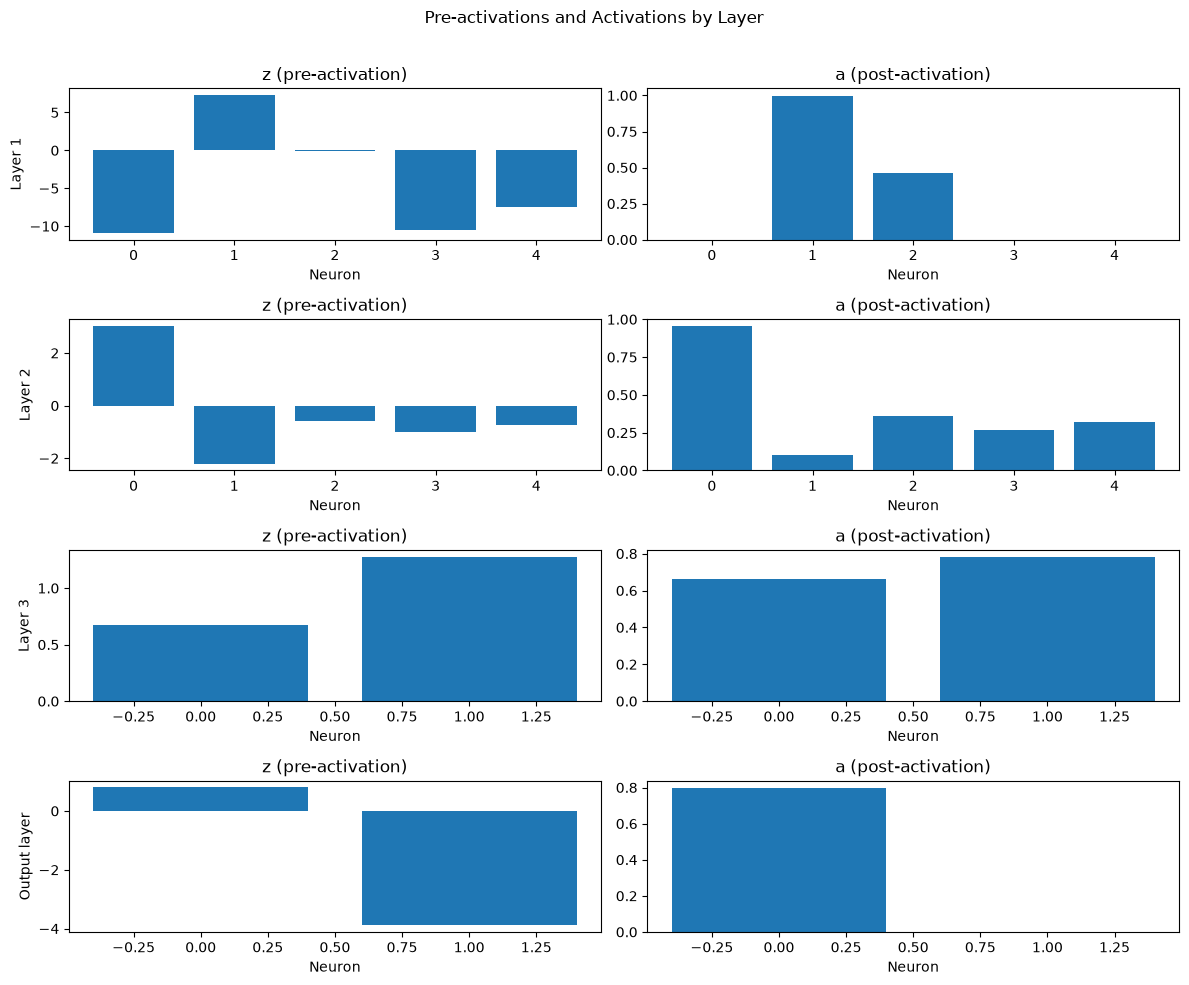

In [5]:
# plot z values and activations from every layer
figure, axes = plt.subplots(
    len(layer_values),
    2,
    figsize=(12, 10),
    squeeze=False,
)

for row, (layer_name, values) in enumerate(layer_values.items()):
    neuron_indices = range(len(values["z"]))

    axes[row, 0].bar(neuron_indices, values["z"])
    axes[row, 0].set_ylabel(layer_name)
    axes[row, 0].set_title("z (pre-activation)")

    axes[row, 1].bar(neuron_indices, values["a"])
    axes[row, 1].set_title("a (post-activation)")

    for column in range(2):
        axes[row, column].set_xlabel("Neuron")

figure.suptitle("Pre-activations and Activations by Layer")
figure.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()